# Solve Inverse Problems - Simulations

Let's try out the inverse module on some simulations.


## 🧪 - Experiment setup
- `fwd`: Forward solution
- `ave`: Measurements
- `ncov`: Noise covariance
- `eig`: Eigenvectors and eigenvalues of the Connectome Lacplacian.
- `gt`: Ground truth

In [1]:
# imports
import mindmap as mm
import mne

# readers
dm = mm.io.TutoManager("../../config.yml")
sr = dm.get_subject("simf10")

# data
fwd = sr.load("fwd", desc="inverse")
ave = sr.load("ave", task="rest", run="11")
ncov = sr.load("cov", task="rest", run="11")
eig = sr.load("eig")

Prepare ground truth

In [2]:
# load ground truth
ground_truth = sr.load("gt", task="rest", run="11")
eeg = sr.load("eeg", task="rest", run="11")

# extract one event
events = mne.events_from_annotations(eeg)[0]
event_time = events[1, 0] / eeg.info["sfreq"]

# crop ground truth
start = event_time - 0.449
stop = event_time + 0.449

gt = ground_truth.copy().crop(tmin=start, tmax=stop)

Used Annotations descriptions: [np.str_('1.0')]


/home/nino/Code/mindmap/mindmap/io/tutorial.py:60: RuntimeWarning: participants.tsv file not found for /home/nino/Code/mindmap/data/sub-simf10/eeg/sub-simf10_task-rest_run-11_eeg.vhdr
  subreader.add_datatype("eeg", "raw", mne_bids.BIDSPath, lambda f: mne_bids.read_raw_bids(f, verbose="warning").load_data(verbose="warning"))


## 🧬 - Data Processing
Estimate regularization parameter

In [3]:
snr, snr_db = mm.analysis.eeg.estimate_evoked_snr(evoked=ave, baseline=(-0.4, -0.1), noise_cov=ncov)
lambda2 = 1.0 / (snr.max()**2)

print(f"Estimated SNR: {snr.max():.3f}")
print(f"Estimated lambda2: {lambda2:.3f}")

    Created an SSP operator (subspace dimension = 1)
Computing rank from covariance with rank=None
    Using tolerance 9.6e-13 (2.2e-16 eps * 203 dim * 21  max singular value)
    Estimated rank (eeg): 202
    EEG: rank 202 computed from 203 data channels with 1 projector
    Setting small EEG eigenvalues to zero (without PCA)
    Created the whitener using a noise covariance matrix with rank 202 (1 small eigenvalues omitted)
Estimated SNR: 20.509
Estimated lambda2: 0.002


Apply inverse solver

In [4]:
# mindmap's inverse solution
inv = mm.analysis.inverse.wCSET(
    forward = fwd,
    noise_cov = ncov,
    depth = 0.8,
    #noise_norm = "sLORETA",
    eigenvectors = eig["vec"],
    eigenvalues = eig["val"],
    harm = 0.7,
)

sol = inv.solve(ave, lambda2)

# MNE-pythons' inverse solution
inv_mne = mne.minimum_norm.make_inverse_operator(
    info = ave.info,
    forward = fwd,
    noise_cov = ncov,
    fixed = True,
    depth = None,
)

stc = mne.minimum_norm.apply_inverse(
    ave,
    inv_mne,
    lambda2,
    method = "sLORETA",
)

Computing inverse operator with 203 channels.
    203 out of 203 channels remain after picking
Selected 203 channels
    Average patch normals will be employed in the rotation to the local surface coordinates....
    Converting to surface-based source orientations...
    [done]
Whitening the forward solution.
    Created an SSP operator (subspace dimension = 1)
Computing rank from covariance with rank=None
    Using tolerance 9.6e-13 (2.2e-16 eps * 203 dim * 21  max singular value)
    Estimated rank (eeg): 202
    EEG: rank 202 computed from 203 data channels with 1 projector
    Setting small EEG eigenvalues to zero (without PCA)
Creating the source covariance matrix
Adjusting source covariance matrix.
Computing SVD of whitened and weighted lead field matrix.
    largest singular value = 2.53292
    scaling factor to adjust the trace = 1.4316e+20 (nchan = 203 nzero = 1)
Preparing the inverse operator for use...
    Scaled noise and source covariance from nave = 1 to nave = 20
    Cre

## 📊 - Visualization

Measurements - timeseries

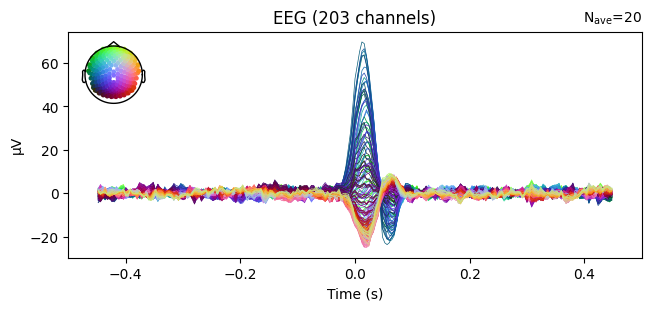

In [5]:
_ = ave.plot(xlim=(-0.5, 0.5))

Measurements - topographies

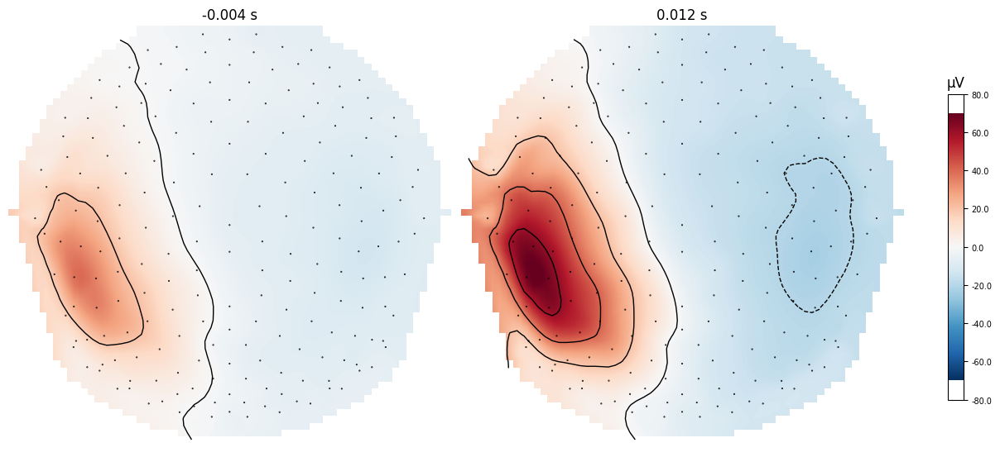

In [6]:
hrp = mm.analysis.eeg.get_rising_phase(ave, ratio=0.5)    # half rising phase
pp  = mm.analysis.eeg.get_rising_phase(ave, ratio=1)      # peak phase

_ = ave.plot_topomap(times=[hrp, pp], size=4, extrapolate="local", outlines=None)

Source reconstruction

In [7]:
mm.viz.plot_source_estimate(
    source_space = fwd["src"],
    timeseries = [sol.copy(), stc.copy(), gt.copy()],
    ts_params={"normalize":"max", "absolute":True}
).show()

Widget(value='<iframe src="http://localhost:36711/index.html?ui=P_0x73a184c8a050_0&reconnect=auto" class="pyvi…

In [8]:
mm.viz.plot_spectrum(eig["vec"].T @ sol.data, times = sol.times).show()

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

class MetricSuite:
    def __init__(self, name="Evaluation"):
        self.name = name
        self._data = []

    def register(self, method, metric, values):
        """Adds results. 'values' can be a single number or a list/array."""
        if not isinstance(values, (list, tuple, pd.Series)):
            values = [values]

        for val in values:
            self._data.append({
                "Method": method,
                "Metric": metric,
                "Value": val,
            })
        return self
    
    def add_from_function(self, method_name, metric_name, func, *args, **kwargs):
        """"""
        result = func(*args, **kwargs)
        return self.register(method_name, metric_name, result)
    
    @property
    def dataframe(self):
        return pd.DataFrame(self._data)
    
    def summary(self):
        """Quick statistical overview."""
        return self.dataframe.groupby(["Metric", "Method"])["Value"].agg("mean", "std", "count")
    
    def plot(self, metrics=None, methods=None, kind="auto", **kwargs):
        """
        Flexible plotting interface.

        Parameters:
        ----------
        metrics: list | str
            Filter for specific metrics.

        methods: list | str
            Filter for specific methods.

        kind: str ['auto', 'box', 'violin', 'bar', or 'heatmap']
            Type of plot.

        **kwargs:
            Passed to the underlying Seaborn/Matplotlib functions.
        """
        
        df = self.dataframe

        # flexible filtering
        if metrics:
            metrics = [metrics] if isinstance(metrics, str) else metrics
            df = df[df["Metric"].isin(metrics)]
        if methods:
            methods = [methods] if isinstance(methods, str) else methods
            df = df[df["Method"].isin(methods)]

        if df.empty:
            print("Query returned no data.")
            return
        
        plot_methods = {
            "box": self._plot_box,
            "violin": self._plot_violin,
            "bar": self._plot_bar,
            "heatmap": self._plot_heatmap,
        }

        if kind not in plot_methods:
            raise ValueError(f"Kind '{kind}' not supported. Choose from {list(plot_methods.keys())}")
        
        return plot_methods[kind](df, **kwargs)

        
    def _plot_heatmap(self, df, **kwargs):
        pivot = df.pivot_table(index="Method", columns="Metric", values="Value", aggfunc="mean")
        sns.heatmap(pivot, annot=True, **kwargs)
        plt.show()

    def _plot_box(self, df, **kwargs):
        """Default style: Boxplot with overlaid raw data points."""
        defaults = {"palette": "viridis", "linewidth": 1.5}
        params = {**defaults, **kwargs}

        g = sns.FacetGrid(df, col="Metric", sharey=False, col_wrap=3)
        g.map_dataframe(sns.boxplot, x="Method", y="Value", hue="Method", **params)
        g.map_dataframe(sns.stripplot, x="Method", y="Value", color=".2", alpha=0.4)
        g.add_legend()
        return g
    
    def _plot_violin(self, df, **kwargs):
        """Default style: Split or inner-quartile violin plots."""
        defaults = {"inner": "quartile", "palette": "muted", "cut":0}
        params = {**defaults, **kwargs}

        g = sns.FacetGrid(df, col="Metric", sharey=False, col_wrap=3)
        g.map_dataframe(sns.violinplot, x="Method", y="Value", hue="Method", **params)
        g.add_legend()
        return g
    
    def _plot_bar(self, df, **kwargs):
        """Default style: Bar chart with error bars (confidence intervals)."""
        defaults = {"errorbar":"sd", "capsize": .1, "palette":"magma"}
        params = {**defaults, **kwargs}

        g = sns.FacetGrid(df, col="Metric", sharey=False, col_wrap=3)
        g.map_dataframe(sns.barplot, x="Method", y="Value", hue="Method", **params)
        g.add_legend()
        return g
    
    def _plot_heatmap(self, df, **kwargs):
        """Default style: Clean matrix with centered annotations."""
        defaults = {"cmap": "RdYlGn", "annot": True, "fmt": ".2f", "cbar_kws": {"label": "Average Value"}}
        params = {**defaults, **kwargs}

        pivot = df.pivot_table(index="Method", columns="Metric", values="Value", aggfunc="mean")
        plt.figure(figsize=(10, 6))
        sns.heatmap(pivot, **params)
        plt.title(f"{self.name} Overview")
        return plt.gca()